# Module 7 Lab 3: Textbook Problem 8.1

### Titanic: Who Survived?

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This lab builds a classifier that guesses whether a Titanic passenger survived. We pick a few features, turn them into numbers the model can use, fill in the missing ages, and grade the model on passengers it never saw. Then we look at which passengers it gets wrong.

**Note on the problem:** the textbook's Problem 8.1 uses a crash-survivor dataset with logistic regression. For this course the professor swapped in the Titanic data and a model we already know (a shallow decision tree), so that's what this notebook does. It's the same idea: predict survived (1) or didn't (0) from a few passenger features.

## Load and look

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier

titanic = pd.read_csv('titanic_train.csv')
print(titanic.shape)
titanic.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [14]:
titanic.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

`Age` is missing for 177 passengers, `Cabin` for most of them, and `Embarked` for 2. `titanic_test.csv` has no `Survived` column, so we can't use it to score anything. Our test set has to come from splitting `titanic_train.csv`.

## Prepare the features

In [15]:
# the model needs numbers, so encode sex as 0/1
titanic['Sex_num'] = titanic['Sex'].map({'male': 0, 'female': 1})

FEATURES = ['Pclass', 'Sex_num', 'Age', 'Fare']   # 2-4 numeric-ready features

X = titanic[FEATURES]
y = titanic['Survived']
X.head()

,Pclass,Sex_num,Age,Fare
0,3,0,22.0,7.2500
1,1,1,38.0,71.2833
2,3,1,26.0,7.9250
3,1,1,35.0,53.1000
4,3,0,35.0,8.0500


We chose `Pclass`, `Sex_num`, `Age`, and `Fare` because they all describe a passenger before the ship sank. Ticket class could affect access to lifeboats, sex could matter because of evacuation priorities, age could affect who got helped, and fare roughly reflects the ticket and cabin. None of them are built from `Survived`, so the answer doesn't leak into the model.

## Split 70/30, then fill in missing ages

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print('missing ages in train:', X_train['Age'].isna().sum())
print('missing ages in test: ', X_test['Age'].isna().sum())

age_median = X_train['Age'].median()
print('median age (training rows only):', age_median)

X_train = X_train.fillna({'Age': age_median})
X_test = X_test.fillna({'Age': age_median})

print('missing after filling:', X_train['Age'].isna().sum() + X_test['Age'].isna().sum())

missing ages in train: 124
missing ages in test:  53
median age (training rows only): 28.0
missing after filling: 0


**How we handled missing ages:** we filled them with the median age (28), like in Module 3, because ages are a bit skewed and the median doesn't get pulled by the older passengers. The textbook uses the mean, which is also fine. We worked out the median from the **training rows only** and then used that same number for the test rows, so no information from the test set leaks into training.

## A baseline to beat

In [17]:
died_rate = 1 - y_test.mean()
print(f'If I just guessed "died" for everyone, I would be right {died_rate:.1%} of the time on the test set.')

If I just guessed "died" for everyone, I would be right 58.6% of the time on the test set.


So a model is only useful if it beats about 59%.

## Fit a shallow decision tree

In [18]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print(f'train accuracy: {tree.score(X_train, y_train):.3f}')
print(f'TEST accuracy:  {tree.score(X_test, y_test):.3f}')

train accuracy: 0.827
TEST accuracy:  0.806


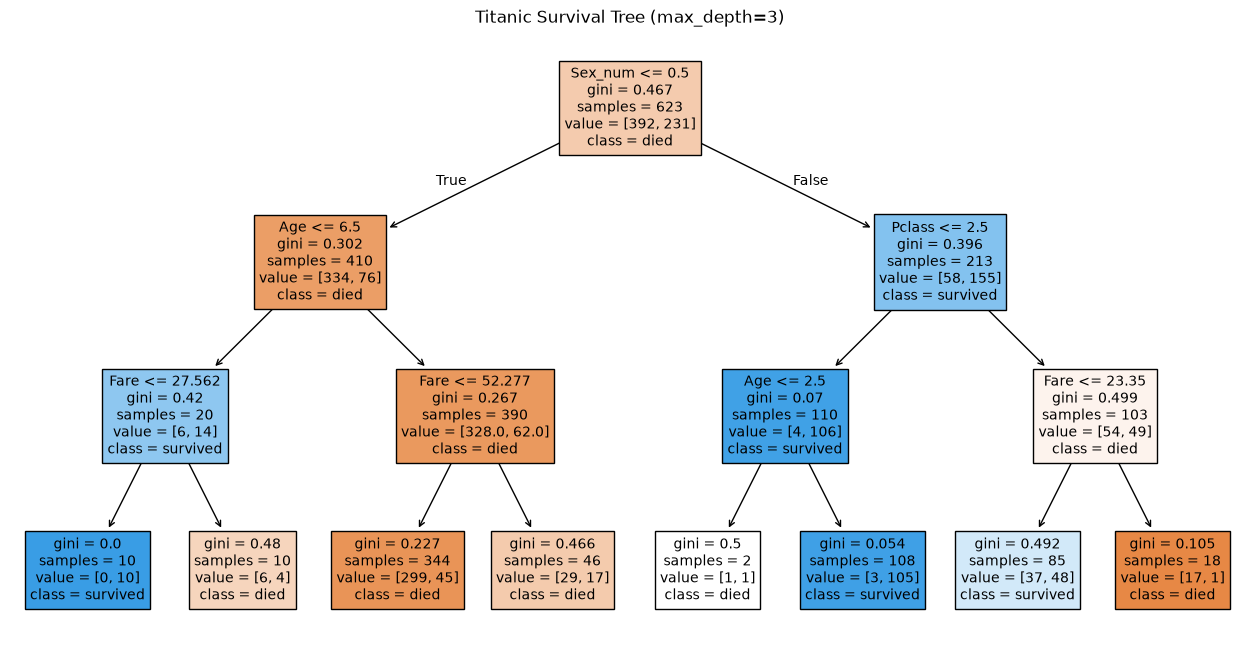

In [19]:
plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=FEATURES, class_names=['died', 'survived'], filled=True)
plt.title('Titanic Survival Tree (max_depth=3)')
plt.show()

Train and test accuracy are close (about 83% vs. 81%), so the tree isn't just memorizing. It beats the 59% baseline by a lot.

### Quick comparison: kNN

In [20]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print(f'kNN TEST accuracy: {knn.score(X_test, y_test):.3f}')

kNN TEST accuracy: 0.687


kNN does a lot worse here. It measures distance between passengers, and `Fare` runs into the hundreds while `Sex_num` is only 0 or 1, so fare basically drowns out sex. The tree doesn't have that problem because it asks one question at a time. We're keeping the tree.

## Who does the model get wrong?

In [21]:
results = titanic.loc[X_test.index, ['Sex', 'Pclass', 'Age', 'Survived']].copy()
results['predicted'] = tree.predict(X_test)
results['wrong'] = results['predicted'] != results['Survived']

pd.crosstab(results['Survived'], results['predicted'],
            rownames=['actual (1 = survived)'], colnames=['predicted'])

predicted,0,1
actual (1 = survived),,
0,140,17
1,35,76


In [22]:
(results.groupby(['Sex', 'Pclass'])
        .agg(passengers=('wrong', 'size'), wrong=('wrong', 'sum'), error_rate=('wrong', 'mean'))
        .round(2))

passengers  wrong  error_rate
Sex    Pclass                               
female 1               33      0        0.00
       2               27      5        0.19
       3               41     13        0.32
male   1               44     20        0.45
       2               25      2        0.08
       3               98     12        0.12

In [23]:
# what kind of mistake: surviving men called "died", or women who died called "survived"?
results[results['wrong']].groupby(['Sex', 'Survived']).size().rename('mistakes')

Sex     Survived
female  0           16
        1            2
male    0            1
        1           33
Name: mistakes, dtype: int64

The tree struggled most with first-class men, getting 20 of 44 wrong (45%). Its most common mistake overall was predicting that men who actually survived had died (33 cases).

## Conclusion

Our shallow decision tree predicted survival correctly for about 81% of the passengers it never saw, well above the 59% we'd get by just guessing "died" for everyone. Sex and ticket class did most of the work, which lines up with how the evacuation actually played out. The model's weak spot is men who survived, especially in first class, since it learned that most men didn't make it and has a hard time spotting the exceptions.

It's still a simple model: only four features, filled-in ages for about 20% of passengers, and one 70/30 split, so the exact accuracy could shift a bit with a different split. Next steps could be adding family features like `SibSp` and `Parch`, scaling the features so kNN gets a fair shot, and using cross-validation to get a steadier accuracy estimate.

## Appendix: AI Use

- **What Claude did:** set up a starting feature list from the lab's suggestions and helped with syntax for encoding `Sex`, filling missing ages, the tree and kNN code, and the error tables.
- **Key prompts (paraphrased):**
  - How can I choose a few useful features for predicting Titanic survival and encode `Sex` for the model?
  - How can I fill in missing ages without using test-set information, then train a shallow decision tree and compare it with kNN?
  - How can I use tables to see which passenger groups the model gets wrong most often?
  - Refine my wording so it reads more professionally.